In [1]:
import gymnasium as gym
from gymnasium import spaces
import numpy as np


class RetrievalEnv(gym.Env):

    def __init__(
        self,
        d=8,
        duplicates_per_evidence=2,
        n_noise_chunks=4,
        max_steps=8,
        noise_std=0.5,
        retrieval_cost=0, #0.2,
        seed=0
    ):

        super().__init__()

        self.d = d

        self.duplicates = duplicates_per_evidence

        self.n_noise_chunks = n_noise_chunks

        self.max_steps = max_steps

        self.noise_std = noise_std

        self.retrieval_cost = retrieval_cost

        #######################################

        self.n_chunks = (

            3*self.duplicates

            +

            self.n_noise_chunks

        )

        #######################################

        rng = np.random.RandomState(seed)

        #######################################
        # Query decomposition
        #######################################

        self.W1 = rng.randn(d,d) + d*np.eye(d)

        A = rng.randn(d,d)

        self.W2 = A + d*np.eye(d)

        B = rng.randn(d,d)

        self.W3 = B + d*np.eye(d)

        #######################################
        # Evidence generation
        #######################################

        C = rng.randn(d,d)

        self.M = C + d*np.eye(d)

        #######################################
        # Answer generation
        #######################################

        self.H = rng.randn(

            d,

            3*d

        )

        #######################################
        # Observation
        #######################################

        obs_dim = (

            d

            +

            self.n_chunks*d

            +

            self.n_chunks

        )

        self.observation_space = spaces.Box(

            low=-np.inf,

            high=np.inf,

            shape=(obs_dim,),

            dtype=np.float32

        )

        #######################################
        # Actions
        #######################################

        self.action_space = spaces.Discrete(

            self.n_chunks + 1

        )
    def reset(
        self,
        seed=None,
        options=None
    ):

        super().reset(seed=seed)

        ########################################################
        # 1. Sample query
        ########################################################

        self.q = np.random.randn(self.d)

        # self.q /= np.linalg.norm(self.q)

        ########################################################
        # 2. Generate sub-queries
        ########################################################

        self.q1 = self.W1 @ self.q
        self.q2 = self.W2 @ self.q
        self.q3 = self.W3 @ self.q

        ########################################################
        # 3. Generate evidence vectors
        ########################################################

        self.v1 = self.M @ self.q1
        self.v2 = self.M @ self.q2
        self.v3 = self.M @ self.q3
        
        self.v1 /= np.linalg.norm(self.v1) + 1e-8
        self.v2 /= np.linalg.norm(self.v2) + 1e-8
        self.v3 /= np.linalg.norm(self.v3) + 1e-8

        ########################################################
        # 4. Generate ground-truth answer
        ########################################################

        self.answer = (

            self.v1 +

            self.v2 +

            self.v3

                    )

        ########################################################
        # 5. Construct chunk collection
        ########################################################

        chunks = []
        labels = []

        # Evidence 1
        for _ in range(self.duplicates):

            chunks.append(
                self.v1 +
                self.noise_std *
                np.random.randn(self.d)
            )

            labels.append(1)

        # Evidence 2
        for _ in range(self.duplicates):

            chunks.append(
                self.v2 +
                self.noise_std *
                np.random.randn(self.d)
            )

            labels.append(2)

        # Evidence 3
        for _ in range(self.duplicates):

            chunks.append(
                self.v3 +
                self.noise_std *
                np.random.randn(self.d)
            )

            labels.append(3)

        # Noise chunks
        for _ in range(self.n_noise_chunks):
            
            v = 20*np.random.randn(self.d)
            v /= (np.linalg.norm(v) + 1e-8)

            chunks.append(v 
            )

            labels.append(0)

        ########################################################
        # 6. Shuffle corpus
        ########################################################

        chunks = np.array(chunks)

        labels = np.array(labels)

        perm = np.random.permutation(
            self.n_chunks
        )

        self.chunks = chunks[perm]

        self.labels = labels[perm]

        ########################################################
        # 7. Retrieval bookkeeping
        ########################################################

        self.mask = np.zeros(
            self.n_chunks,
            dtype=np.float32
        )

        self.selected_chunks = []

        self.num_selected = 0

        ########################################################
        # 8. Return observation
        ########################################################

        return self._get_obs(), {}

    def _get_obs(self):

        return np.concatenate(

            [

                self.q,

                self.chunks.flatten(),

                self.mask

            ]

        ).astype(np.float32)
    def step(self, action):

        ########################################################
        # STOP action
        ########################################################

        if action == self.n_chunks:

            recovered = {

                1: np.zeros(self.d),
                2: np.zeros(self.d),
                3: np.zeros(self.d),
                4: np.zeros(self.d)

            }

            prototypes = {

                1: self.v1,
                2: self.v2,
                3: self.v3

            }

            for idx in self.selected_chunks:

                label = self.labels[idx]

                if label > 0:

                    recovered[label] = prototypes[label]
                else: 
                    recovered[4] += self.chunks[idx]
                

            ####################################################
            # Reconstruct answer
            ####################################################

#             V_hat = np.concatenate([

#                 recovered[1],
#                 recovered[2],
#                 recovered[3]

#             ])

#             answer_hat = self.H @ V_hat
            
#             self.answer = (

#             self.v1 +

#             self.v2 +

#             self.v3

#                     )
            answer_hat = (

                recovered[1]

                +

                recovered[2]

                +

                recovered[3]
                
                +
                
                recovered[4]

            )
    
    
    
    

            ####################################################
            # Reward
            ####################################################

            error = np.linalg.norm(

                answer_hat - self.answer

            )

            reward = -1*error

            reward -= (

                self.retrieval_cost *

                self.num_selected

            )

            return (

                self._get_obs(),

                reward,

                True,

                False,

                {}

            )

        ########################################################
        # Repeated retrieval
        ########################################################

        if self.mask[action] == 1:

            return (

                self._get_obs(),

                -10.0,

                True,

                False,

                {}

            )

        ########################################################
        # Retrieve chunk
        ########################################################

        self.mask[action] = 1

        self.selected_chunks.append(action)

        self.num_selected += 1

        ########################################################
        # Budget exhausted
        ########################################################

        if self.num_selected >= self.max_steps:

            recovered = {

                1: np.zeros(self.d),
                2: np.zeros(self.d),
                3: np.zeros(self.d),
                4: np.zeros(self.d)

            }

            prototypes = {

                1: self.v1,
                2: self.v2,
                3: self.v3

            }

            for idx in self.selected_chunks:

                label = self.labels[idx]

                if label > 0:

                    recovered[label] = prototypes[label]
                else:
                    recovered[4] += self.chunks[idx]
                    

            answer_hat = (

                recovered[1]

                +

                recovered[2]

                +

                recovered[3]
                
                + 
                
                recovered[4]

            )

            error = np.linalg.norm(

                answer_hat - self.answer

            )

            reward = -1*error

            reward -= (

                self.retrieval_cost *

                self.num_selected

            )

            return (

                self._get_obs(),

                reward,

                True,

                False,

                {}

            )

        ########################################################
        # Continue retrieval
        ########################################################

        return (

            self._get_obs(),

            0.0,

            False,

            False,

            {}

        )


In [2]:
env = RetrievalEnv()

obs, _ = env.reset()

print(obs.shape)

print(env.labels)

print(env.chunks.shape)

print(env.answer.shape)

(98,)
[0 1 3 0 2 1 2 3 0 0]
(10, 8)
(8,)


In [3]:
import random
import numpy as np
import torch

SEED = 0

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

In [4]:
env = RetrievalEnv(
    d=6,
    duplicates_per_evidence=2,
    n_noise_chunks=4,
    max_steps=8,
    noise_std=0.001,
    retrieval_cost=0.4
)

In [5]:
get_ipython().system('pip install stable-baselines3')

from stable_baselines3 import DQN

policy_kwargs = dict(

    net_arch=[128,128,128]

)

model = DQN(

    "MlpPolicy",

    env,

    learning_rate=1e-3,

    buffer_size=100000,

    learning_starts=1000,

    batch_size=64,

    gamma=1,

    train_freq=4,

    gradient_steps=1,

    target_update_interval=1000,

    exploration_fraction=0.4,

    exploration_final_eps=0.03,

    policy_kwargs=policy_kwargs,

    verbose=0

)


In [6]:
def evaluate(model, env, episodes=100):

    success = 0

    coverage = []

    lengths = []

    for _ in range(episodes):

        obs, _ = env.reset()

        done = False

        retrieved = []

        while not done:

            action, _ = model.predict(
                obs,
                deterministic=True
            )

            obs, reward, done, _, _ = env.step(action)

            if action != env.n_chunks:

                retrieved.append(action)

        labels = [

            env.labels[i]

            for i in retrieved

            if env.labels[i] > 0

        ]

        unique = len(set(labels))

        coverage.append(unique / 3)

        lengths.append(len(retrieved))

        if unique == 3:

            success += 1

    return (

        success / episodes,

        np.mean(coverage),

        np.mean(lengths)

    )


In [7]:
TOTAL = 1000000

INTERVAL = 10000

SUCCESS_TARGET = 0.60
COVERAGE_TARGET = 0.80

timesteps = []

success_curve = []

coverage_curve = []

length_curve = []

for t in range(0, TOTAL, INTERVAL):

    model.learn(

        total_timesteps=INTERVAL,

        reset_num_timesteps=False

    )

    s, c, l = evaluate(

        model,

        env,

        episodes=100

    )

    timesteps.append(

        t + INTERVAL

    )

    success_curve.append(s)

    coverage_curve.append(c)

    length_curve.append(l)

    print(

        t+INTERVAL,

        s,

        c,

        l

    )

    ####################################
    # Early stopping
    ####################################

    if s >= SUCCESS_TARGET and c >= COVERAGE_TARGET:
        print("\nEarly stopping criterion satisfied.")
        print(f"Training stopped at {t+INTERVAL} timesteps.")
        break

10000 0.05 0.47666666666666657 2.58
20000 0.23 0.6433333333333333 3.94
30000 0.03 0.4533333333333333 2.33
40000 0.22 0.6133333333333334 3.31
50000 0.12 0.56 2.61
60000 0.1 0.5700000000000001 2.85
70000 0.14 0.6366666666666667 3.12
80000 0.08 0.5566666666666665 2.41
90000 0.14 0.6166666666666667 2.6
100000 0.29 0.7066666666666667 3.33
110000 0.26 0.6666666666666667 3.09
120000 0.2 0.6800000000000002 3.01
130000 0.25 0.7100000000000002 3.15
140000 0.23 0.6933333333333336 2.78
150000 0.08 0.6033333333333334 2.48
160000 0.24 0.7066666666666669 2.75
170000 0.31 0.73 2.94
180000 0.39 0.7766666666666667 3.28
190000 0.26 0.6933333333333335 2.88
200000 0.42 0.7766666666666667 3.17
210000 0.51 0.8266666666666665 3.44
220000 0.16 0.6600000000000001 2.76
230000 0.31 0.7133333333333334 3.02
240000 0.37 0.7700000000000001 2.89
250000 0.26 0.6933333333333336 2.94
260000 0.22 0.6966666666666669 2.77
270000 0.25 0.7133333333333334 2.95
280000 0.31 0.7533333333333334 3.09
290000 0.28 0.7366666666666666 

In [ ]:
# model.learn(
#     total_timesteps=500000,
#     reset_num_timesteps=False
# )

In [8]:
obs, _ = env.reset()

# print("=" * 70)
# print("GROUND TRUTH")
# print("=" * 70)

# print("\nQuery (q):")
# print(env.q)

# print("\nEvidence v1:")
# print(env.v1)

# print("\nEvidence v2:")
# print(env.v2)

# print("\nEvidence v3:")
# print(env.v3)

# print("\nGround Truth Answer:")
# print(env.answer)

# print("\n")

# print("=" * 70)
# print("CHUNK INVENTORY")
# print("=" * 70)

for i in range(env.n_chunks):

    if env.labels[i] == 0:
        name = "Noise"
    else:
        name = f"E{env.labels[i]}"

#     print(f"Chunk {i:2d} -> {name}")
#     print(env.chunks[i])
#     print()

# print("=" * 70)
# print("DQN RETRIEVAL")
# print("=" * 70)

done = False

total_reward = 0

retrieved = []

while not done:

    action, _ = model.predict(
        obs,
        deterministic=True
    )

    if action == env.n_chunks:

        print("STOP")

    else:

        print(
            f"Retrieve Chunk {action} "
            f"(E{env.labels[action]})"
        )

        retrieved.append(action)

    obs, reward, done, _, _ = env.step(action)

    total_reward += reward

print()

print("=" * 70)
print("SUMMARY")
print("=" * 70)

print("Retrieved chunks :", retrieved)

print("Retrieved labels :",
      [env.labels[i] for i in retrieved])

print("Chunks retrieved :", len(retrieved))

print("Reward :", total_reward)


Retrieve Chunk 6 (E2)
Retrieve Chunk 1 (E1)
Retrieve Chunk 0 (E1)
Retrieve Chunk 5 (E3)
STOP

SUMMARY
Retrieved chunks : [array(6), array(1), array(0), array(5)]
Retrieved labels : [np.int64(2), np.int64(1), np.int64(1), np.int64(3)]
Chunks retrieved : 4
Reward : -1.6


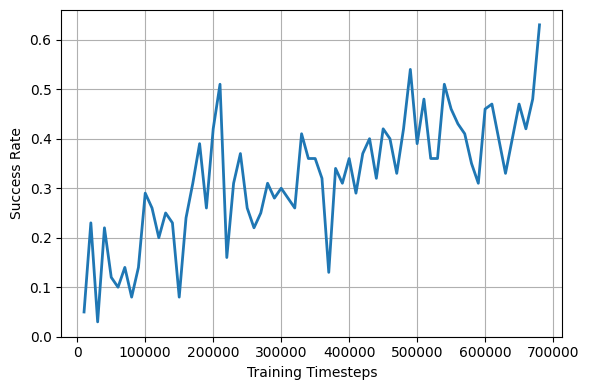

In [9]:
!pip install matplotlib
import matplotlib.pyplot as plt
plt.figure(figsize=(6,4))

plt.plot(

    timesteps,

    success_curve,

    linewidth=2

)

plt.xlabel("Training Timesteps")

plt.ylabel("Success Rate")

plt.grid(True)

plt.tight_layout()

plt.savefig(
    "success_rate.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

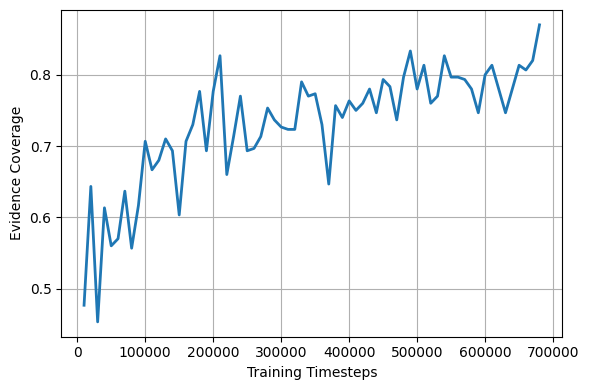

In [10]:
plt.figure(figsize=(6,4))

plt.plot(

    timesteps,

    coverage_curve,

    linewidth=2

)

plt.xlabel("Training Timesteps")

plt.ylabel("Evidence Coverage")

plt.grid(True)

plt.tight_layout()

plt.savefig(
    "coverage_curve.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

In [11]:
import numpy as np
from math import ceil

N_RUNS = 5
N_EPISODES = 1000

success_runs = []
coverage_runs = []
length_runs = []

for run in range(N_RUNS):

    success = 0
    coverage = []
    lengths = []

    for ep in range(N_EPISODES):

        obs, _ = env.reset()

        done = False

        retrieved = []

        while not done:

            action, _ = model.predict(
                obs,
                deterministic=True
            )
            
#             print(action)

            obs, reward, done, _, _ = env.step(action)

            if action != env.n_chunks:
                retrieved.append(action)

        labels = [

            env.labels[i]

            for i in retrieved

            if env.labels[i] > 0

        ]

        unique = len(set(labels))

        coverage.append(unique / 3)

        if unique == 3:
            success += 1

        lengths.append(len(retrieved))

    success_runs.append(success / N_EPISODES)
    coverage_runs.append(np.mean(coverage))
    length_runs.append(np.mean(lengths))

OURS_LENGTH = np.mean(length_runs)

K = max(1, ceil(OURS_LENGTH))

ours_success = np.mean(success_runs)
ours_success_std = np.std(success_runs)

ours_cov = np.mean(coverage_runs)
ours_cov_std = np.std(coverage_runs)

ours_len = np.mean(length_runs)
ours_len_std = np.std(length_runs)

print("OURS")
print(f"Success      : {ours_success:.3f} ± {ours_success_std:.3f}")
print(f"Coverage     : {ours_cov:.3f} ± {ours_cov_std:.3f}")
print(f"Retrieval Len: {ours_len:.3f} ± {ours_len_std:.3f}")
print("K =", K)


OURS
Success      : 0.628 ± 0.006
Coverage     : 0.871 ± 0.003
Retrieval Len: 3.866 ± 0.012
K = 4


In [12]:
success_runs = []
coverage_runs = []

for run in range(N_RUNS):

    success = 0
    coverage = []

    for ep in range(N_EPISODES):

        env.reset()

        scores = []

        for chunk in env.chunks:

            s = np.dot(
                env.q,
                chunk
            ) / (

                np.linalg.norm(env.q)
                *
                np.linalg.norm(chunk)

                + 1e-8

            )

            scores.append(s)

        topk = np.argsort(scores)[::-1][:K]

        labels = [

            env.labels[i]

            for i in topk

            if env.labels[i] > 0

        ]

        unique = len(set(labels))

        coverage.append(unique / 3)

        if unique == 3:
            success += 1

    success_runs.append(success / N_EPISODES)
    coverage_runs.append(np.mean(coverage))

cos_success = np.mean(success_runs)
cos_success_std = np.std(success_runs)

cos_cov = np.mean(coverage_runs)
cos_cov_std = np.std(coverage_runs)

print("COSINE")
print(f"Success : {cos_success:.3f} ± {cos_success_std:.3f}")
print(f"Coverage: {cos_cov:.3f} ± {cos_cov_std:.3f}")


COSINE
Success : 0.008 ± 0.003
Coverage: 0.669 ± 0.001


In [13]:
success_runs = []
coverage_runs = []

for run in range(N_RUNS):

    success = 0
    coverage = []

    for ep in range(N_EPISODES):

        env.reset()

        dist = []

        for chunk in env.chunks:

            d = np.linalg.norm(

                env.q

                -

                chunk

            )

            dist.append(d)

        topk = np.argsort(dist)[:K]

        labels = [

            env.labels[i]

            for i in topk

            if env.labels[i] > 0

        ]

        unique = len(set(labels))

        coverage.append(unique / 3)

        if unique == 3:
            success += 1

    success_runs.append(success / N_EPISODES)
    coverage_runs.append(np.mean(coverage))

euc_success = np.mean(success_runs)
euc_success_std = np.std(success_runs)

euc_cov = np.mean(coverage_runs)
euc_cov_std = np.std(coverage_runs)

print("EUCLIDEAN")
print(f"Success : {euc_success:.3f} ± {euc_success_std:.3f}")
print(f"Coverage: {euc_cov:.3f} ± {euc_cov_std:.3f}")



EUCLIDEAN
Success : 0.013 ± 0.002
Coverage: 0.671 ± 0.001


In [14]:
#model.save("retrieval_dqn")

In [ ]:
from stable_baselines3 import DQN

model = DQN.load("retrieval_dqn")

In [15]:
# np.savez(

#     "training_logs.npz",

#     timesteps=timesteps,

#     success=success_curve,

#     coverage=coverage_curve,

#     length=length_curve

# )

In [ ]:
logs = np.load("training_logs.npz")

timesteps = logs["timesteps"]
success = logs["success"]
coverage = logs["coverage"]
length = logs["length"]

In [ ]:
success